# Libraries

In [12]:
import sklearn as sk
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Global variables

In [13]:
target = "Diabetes_012"

# Helper Function

In [14]:
def divider():
    print("\n\n--------------------------------------------------------------------\n\n")

# Dataset Loading and Audit

No.of Rows: 236378
No.of Columns: 22


--------------------------------------------------------------------


Diabetes_012            float64
HighBP                    int64
HighChol                float64
CholCheck                 int64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity              int64
Fruits                    int64
Veggies                   int64
HvyAlcoholConsump         int64
AnyHealthcare             int64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                       int64
Age                       int64
Education               float64
Income                  float64
dtype: object


--------------------------------------------------------------------


Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck            

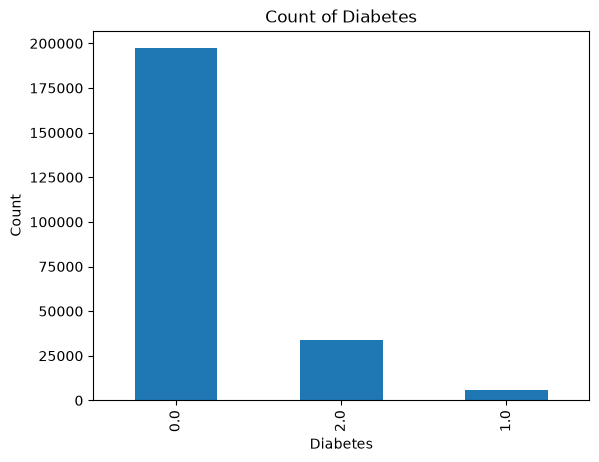

In [15]:
df = pd.read_csv("../data/diabetes_012_health_indicators_BRFSS2021.csv")
print(f"No.of Rows: {df.shape[0]}")
print(f"No.of Columns: {df.shape[1]}")
divider()
print(df.dtypes)
divider()
print(df.isna().sum())
divider()
df["Diabetes_012"].value_counts().plot(kind="bar")
print("0: No diabetes\n1: Pre-diabetes\n2: Diabetes")
plt.xlabel("Diabetes")
plt.ylabel("Count")
plt.title("Count of Diabetes")
plt.show()

# EDA

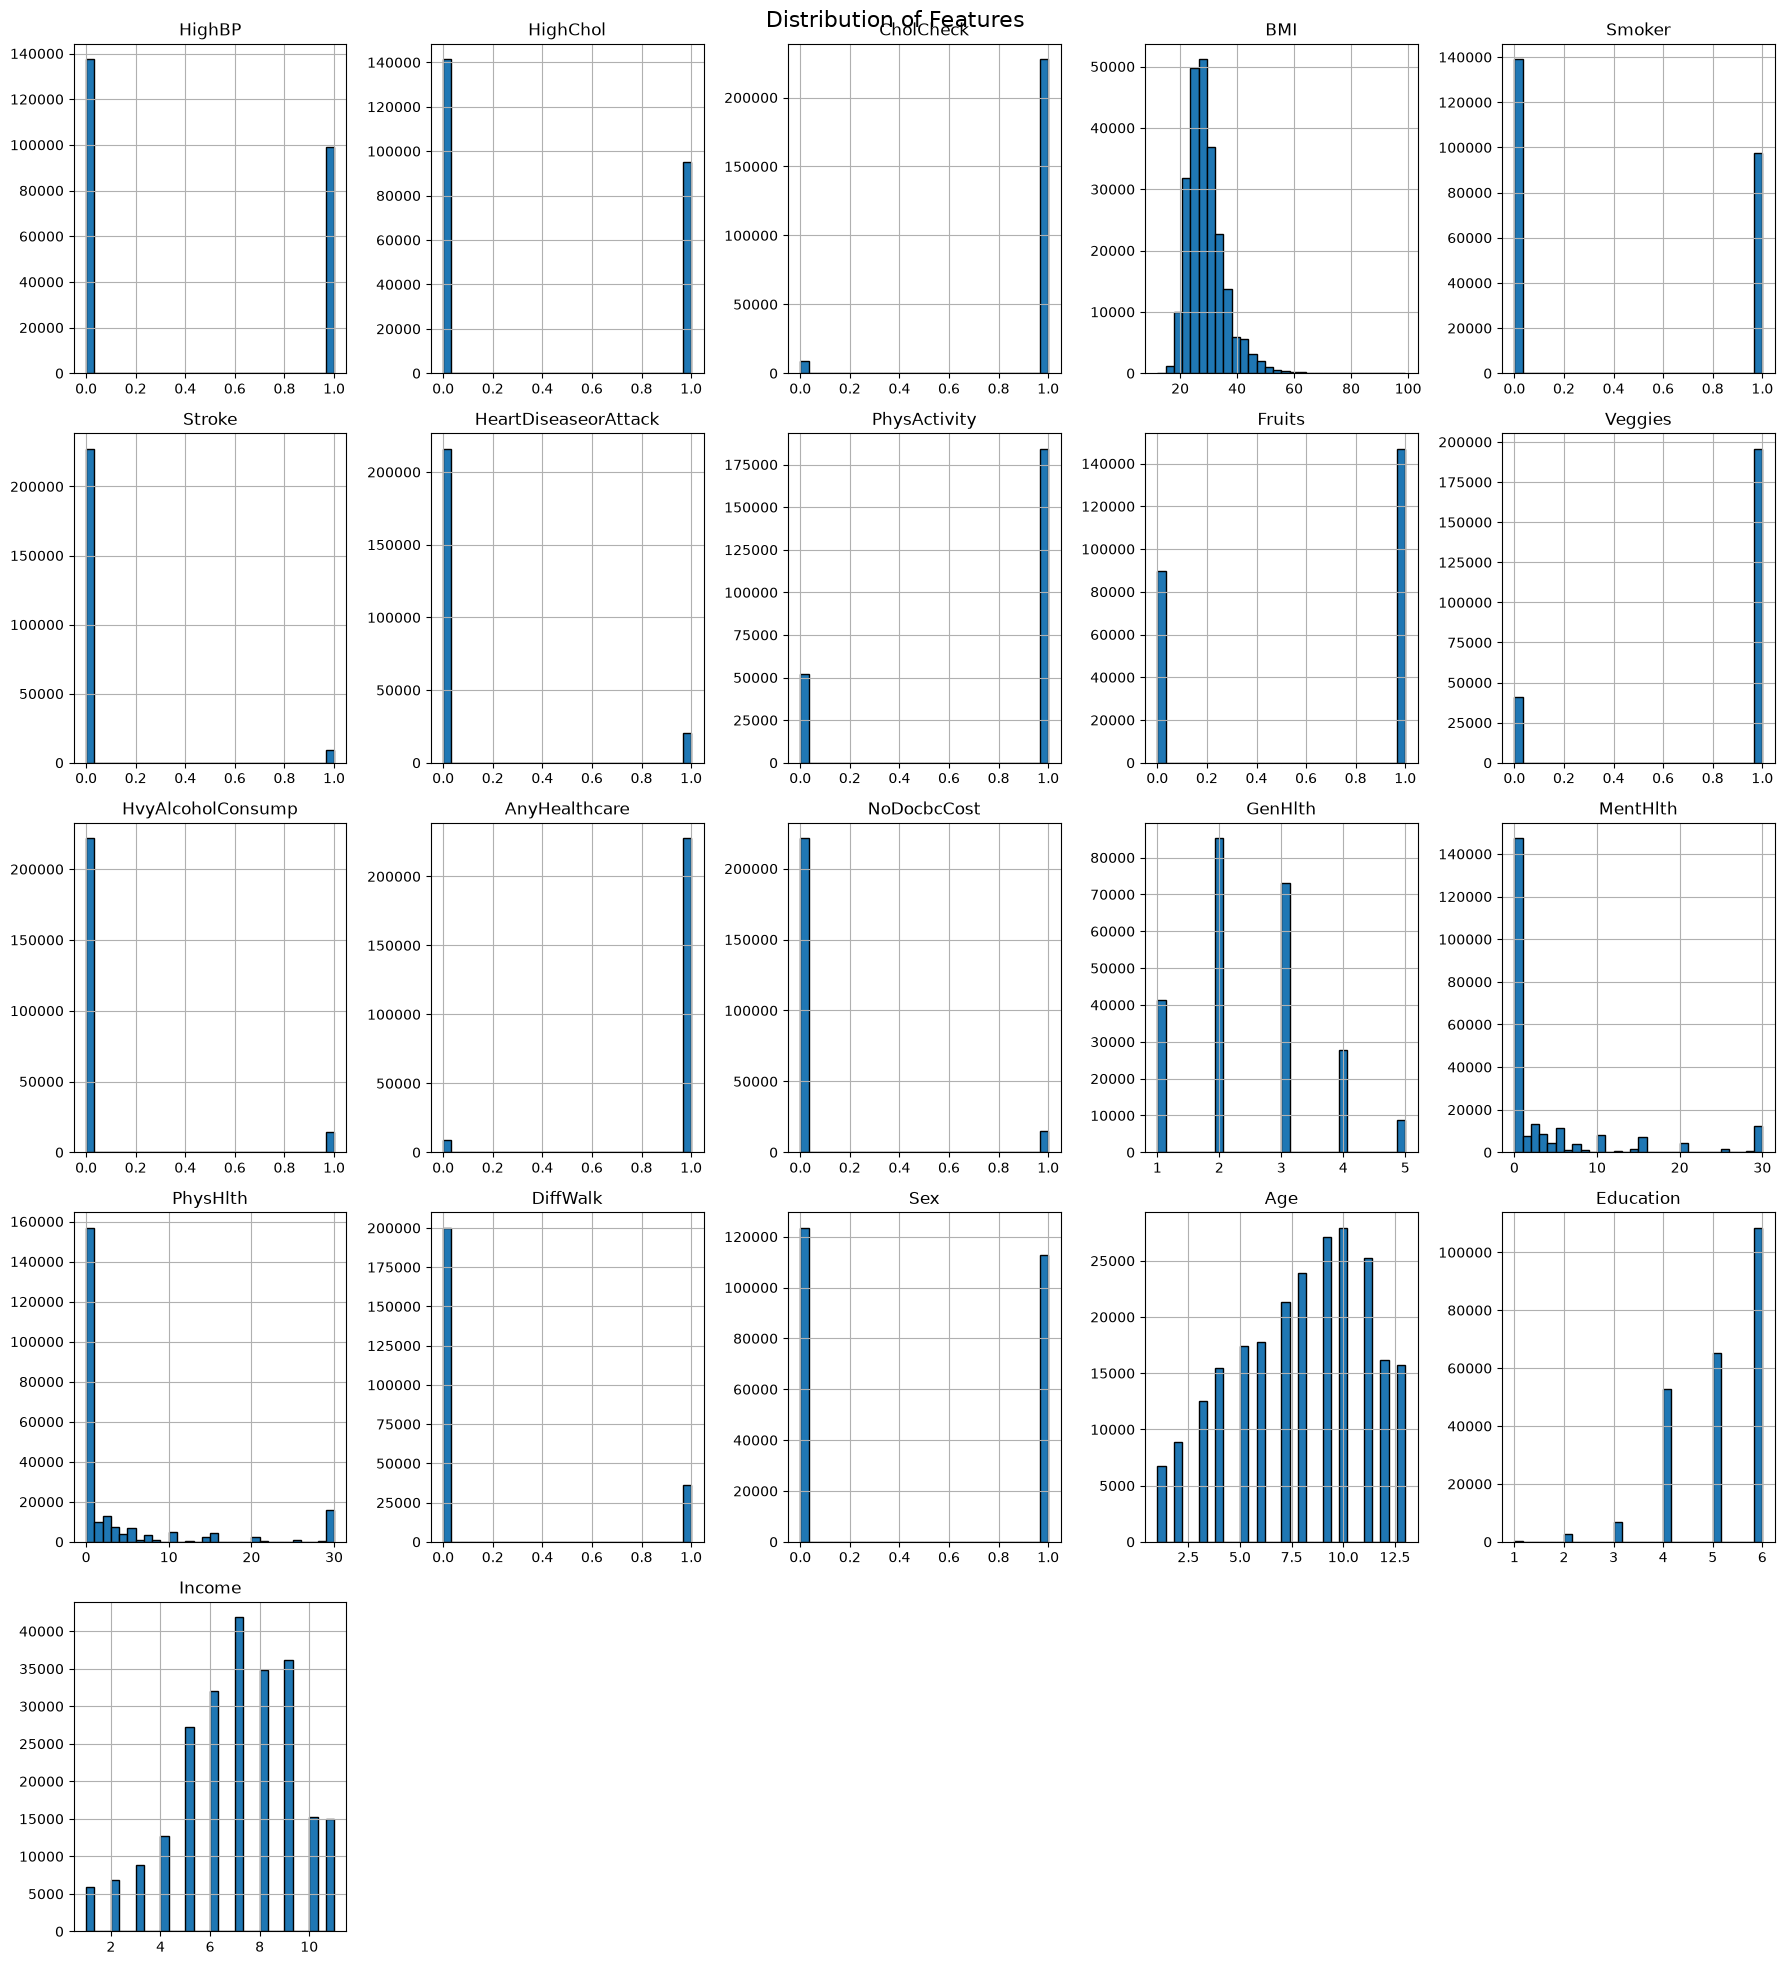



--------------------------------------------------------------------




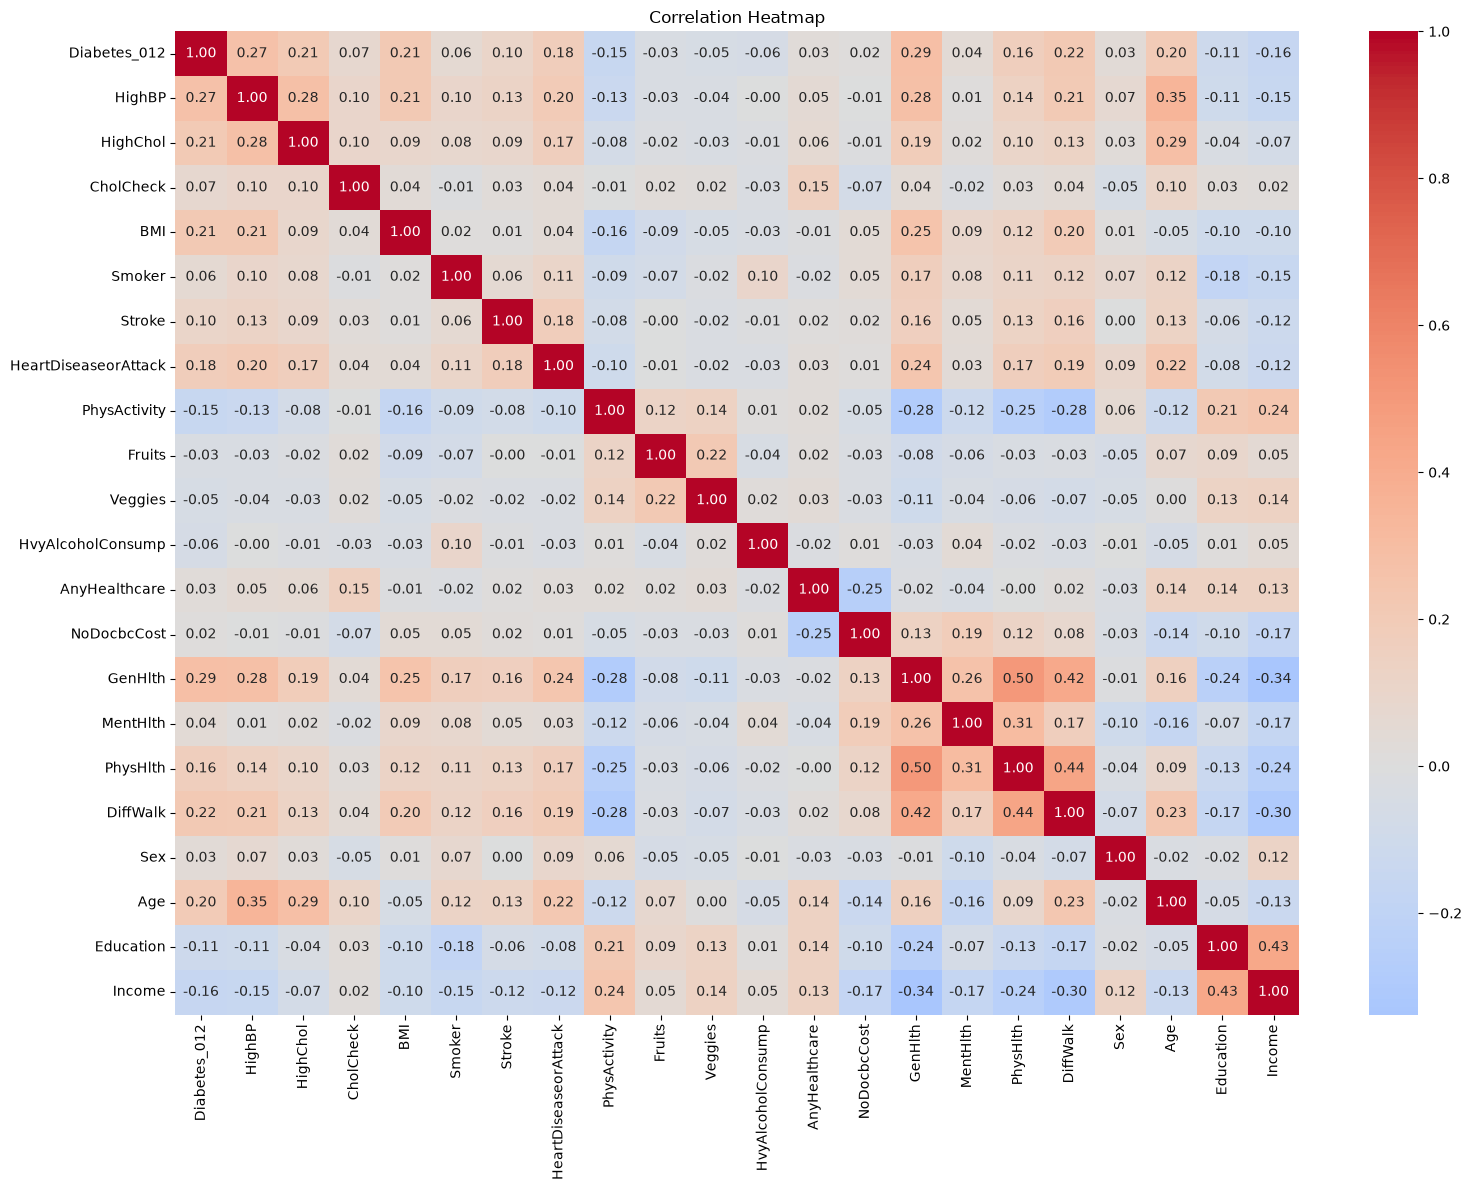



--------------------------------------------------------------------




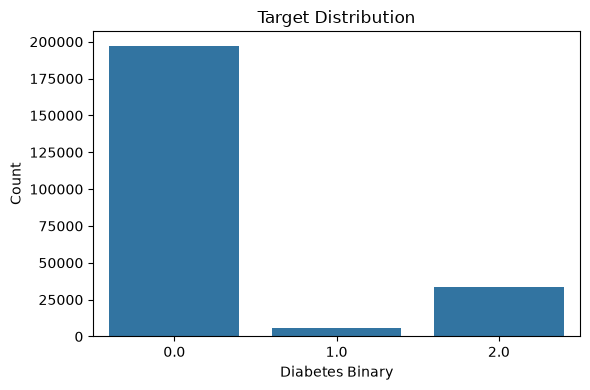



--------------------------------------------------------------------




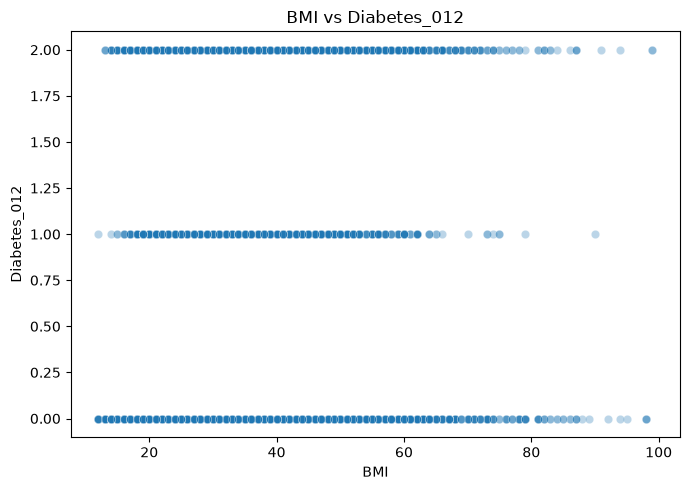

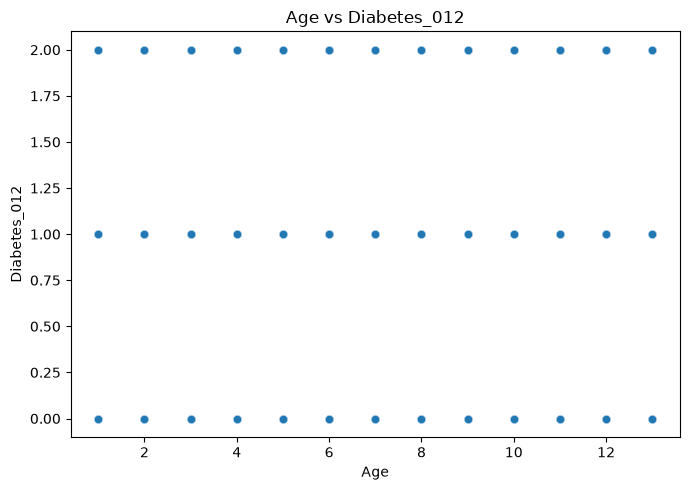

In [16]:
X = df.drop(columns=[target])
y = df[target]


# --------------------------------------------------
# 1. Distribution plots for each feature
# --------------------------------------------------

X.hist(
    bins=30,
    figsize=(18, 20),
    edgecolor="black"
)

plt.suptitle("Distribution of Features", fontsize=16)
plt.tight_layout()
plt.show()
divider()

# --------------------------------------------------
# 2. Correlation heatmap
# --------------------------------------------------

plt.figure(figsize=(16, 12))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
divider()

# --------------------------------------------------
# 3. Target distribution
# --------------------------------------------------

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x=target
)

plt.title("Target Distribution")
plt.xlabel("Diabetes Binary")
plt.ylabel("Count")
plt.tight_layout()
plt.show()
divider()

# --------------------------------------------------
# 4. Feature-target scatter plots
# --------------------------------------------------

feature1 = "BMI"
feature2 = "Age"

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x=feature1,
    y=target,
    alpha=0.3
)

plt.title(f"{feature1} vs {target}")
plt.xlabel(feature1)
plt.ylabel(target)
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x=feature2,
    y=target,
    alpha=0.3
)

plt.title(f"{feature2} vs {target}")
plt.xlabel(feature2)
plt.ylabel(target)
plt.tight_layout()
plt.show()

### TODO: interpretation

# Data cleaning

In [17]:

print("Missing values:")
# Check missing values in each column
print(df.isnull().sum())
divider()

print("Percentage of missing values:")
# Check percentage of missing values
print(df.isnull().mean() * 100)
divider()


# Handle missing values
for col in df.columns:
    if df[col].dtype in ["int64", "float64"]:
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])


print("After handling missing values:")
print(df.isnull().sum())
divider()

# Count duplicate rows
print("Duplicate rows count:", df.duplicated().sum())
divider()

print("Duplicated rows:")
# Display duplicate rows
print(df[df.duplicated()])
divider()

# Remove duplicate rows, keeping the first occurrence
df = df.drop_duplicates()

print("Duplicates after removal:", df.duplicated().sum())


divider()
min_count = df[target].value_counts().min()

df = (
    df.groupby(target)
      .sample(n=min_count, random_state=42)
      .reset_index(drop=True)
)
print(df[target].value_counts())

Missing values:
Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


--------------------------------------------------------------------


Percentage of missing values:
Diabetes_012            0.0
HighBP                  0.0
HighChol                0.0
CholCheck               0.0
BMI                     0.0
Smoker                  0.0
Stroke                  0.0
HeartDiseaseorAttack    0.0
PhysActivity            0.0
Fruits                  0.0
Veggies         

# Encoding, scaling & splitting

In [18]:
# Separate features and known labels
X = df.drop(columns=[target])
y = df[target]  # Used only for stratification/evaluation

# 2. Identify numerical and categorical columns
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

# 3. Stratified train/test split
X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Preprocessing
# Scale numerical features and one-hot encode categoricals
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

# Fit only on training features
X_train_scaled = preprocessor.fit_transform(X_train)

# Transform test features using training-fitted parameters
X_test_scaled = preprocessor.transform(X_test)


Numerical columns: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
Categorical columns: []


# Feature engineering

In [19]:
#TODO 

# K-Means Clustering

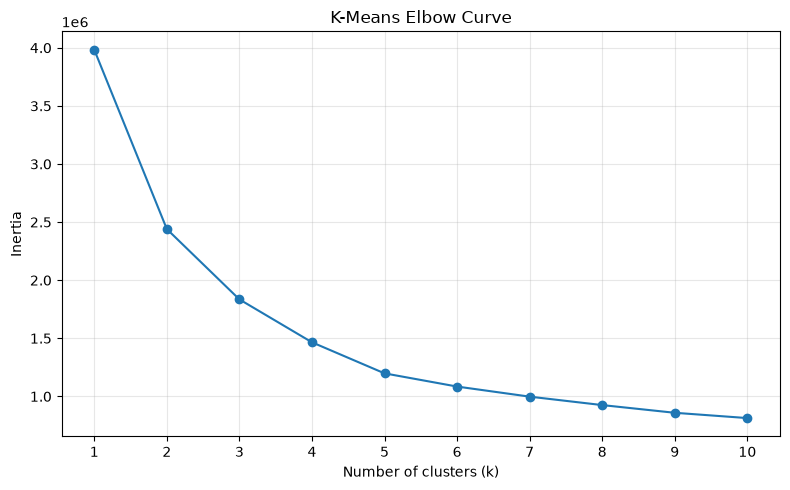

K-Means cluster labels: [0 1 2]
K-Means cluster sizes: [ 1954 13067  1818]
K-Means inertia: 1834917.5472

K-Means Evaluation Metrics
Algorithm  Clusters  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
  K-Means         3            0.5268                0.9653                1242.8532


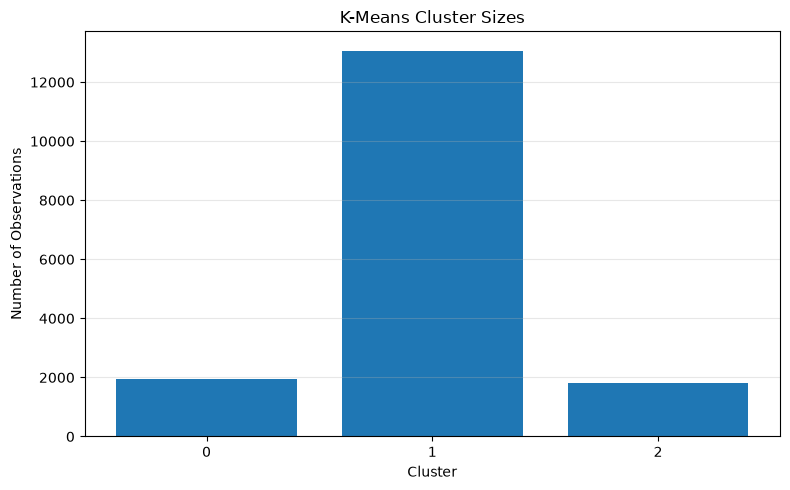

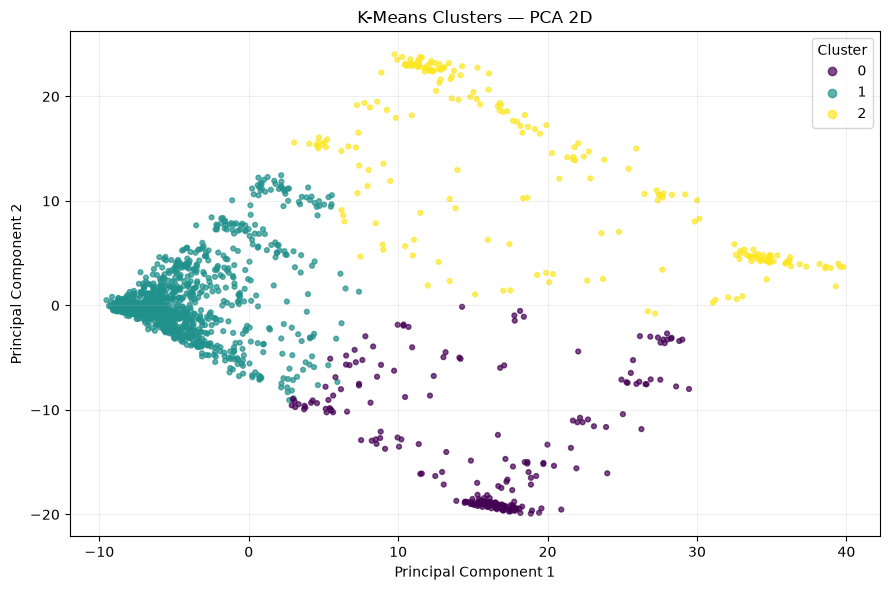

PCA variance explained: 73.15 %


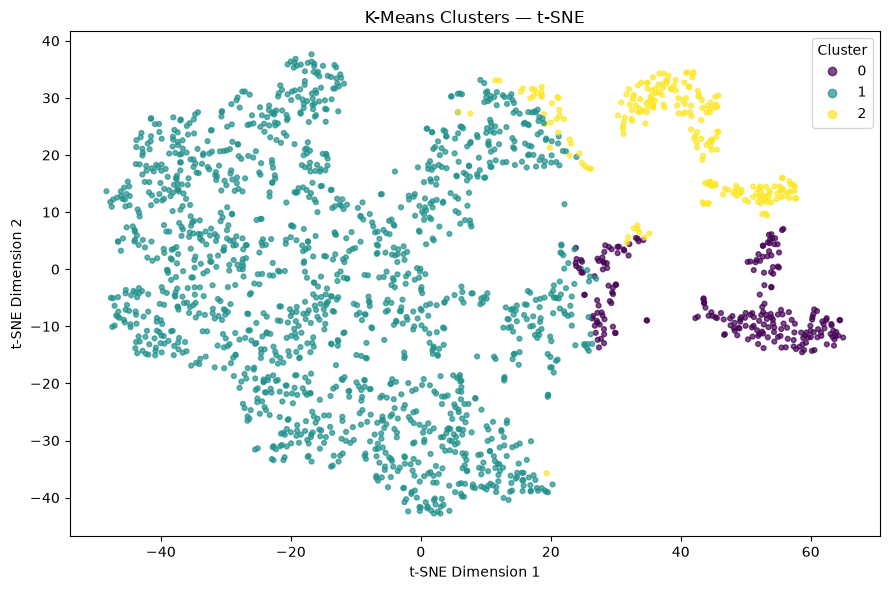

In [20]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# ==========================================
# 1. PREPARE DATA
# ==========================================
X_array = X.to_numpy() if hasattr(X, "to_numpy") else np.asarray(X)
X_array = np.asarray(X_array, dtype=np.float64)

if not np.isfinite(X_array).all():
    raise ValueError("Clean missing and infinite values in X first.")

rng = np.random.default_rng(42)
sample_size = min(2000, len(X_array))
sample_idx = np.sort(
    rng.choice(len(X_array), sample_size, replace=False)
)
X_compare = X_array[sample_idx]

# ==========================================
# 2. ELBOW CURVE
# ==========================================
k_values = range(1, min(11, len(X_array) + 1))
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_array)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Curve")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Select k after inspecting the elbow curve
chosen_k = 3

# ==========================================
# 3. FIT K-MEANS ON FULL DATASET
# ==========================================
kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans.fit_predict(X_array)

print("K-Means cluster labels:", np.unique(kmeans_labels))
print("K-Means cluster sizes:", np.bincount(kmeans_labels))
print("K-Means inertia:", round(kmeans.inertia_, 4))

# Use the full-data model's labels on the evaluation sample
sample_labels = kmeans_labels[sample_idx]

# ==========================================
# 4. EVALUATION METRICS
# ==========================================
kmeans_metrics = pd.DataFrame([{
    "Algorithm": "K-Means",
    "Clusters": len(np.unique(sample_labels)),
    "Silhouette Score": silhouette_score(
        X_compare, sample_labels
    ),
    "Davies-Bouldin Index": davies_bouldin_score(
        X_compare, sample_labels
    ),
    "Calinski-Harabasz Index": calinski_harabasz_score(
        X_compare, sample_labels
    )
}])

print("\nK-Means Evaluation Metrics")
print(kmeans_metrics.round(4).to_string(index=False))

# ==========================================
# 5. CLUSTER SIZE VISUALISATION
# ==========================================
cluster_ids, cluster_counts = np.unique(
    kmeans_labels, return_counts=True
)

plt.figure(figsize=(8, 5))
plt.bar(cluster_ids, cluster_counts)
plt.xlabel("Cluster")
plt.ylabel("Number of Observations")
plt.title("K-Means Cluster Sizes")
plt.xticks(cluster_ids)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 6. PCA 2D VISUALISATION
# ==========================================
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_compare)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=sample_labels,
    cmap="viridis",
    s=12,
    alpha=0.7
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters — PCA 2D")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "PCA variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# ==========================================
# 7. t-SNE VISUALISATION
# ==========================================
tsne = TSNE(
    n_components=2,
    perplexity=min(30, (len(X_compare) - 1) / 3),
    init="pca",
    learning_rate="auto",
    random_state=42
)
X_tsne = tsne.fit_transform(X_compare)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=sample_labels,
    cmap="viridis",
    s=12,
    alpha=0.7
)
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("K-Means Clusters — t-SNE")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()


# Agglomerative Hierarchical Clustering


Linkage: single
Cluster labels: [0 1 2]
Cluster sizes: [1998    1    1]

Linkage: complete
Cluster labels: [0 1 2]
Cluster sizes: [  67 1715  218]

Linkage: average
Cluster labels: [0 1 2]
Cluster sizes: [1807  185    8]

Linkage: ward
Cluster labels: [0 1 2]
Cluster sizes: [ 357 1391  252]

AGGLOMERATIVE CLUSTERING METRICS
               Algorithm  Clusters  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
  Agglomerative - single         3            0.4372                0.3881                   5.4805
Agglomerative - complete         3            0.5136                1.2514                 659.6707
 Agglomerative - average         3            0.5168                0.8208                 468.1553
    Agglomerative - ward         3            0.4093                1.1628                1026.2918


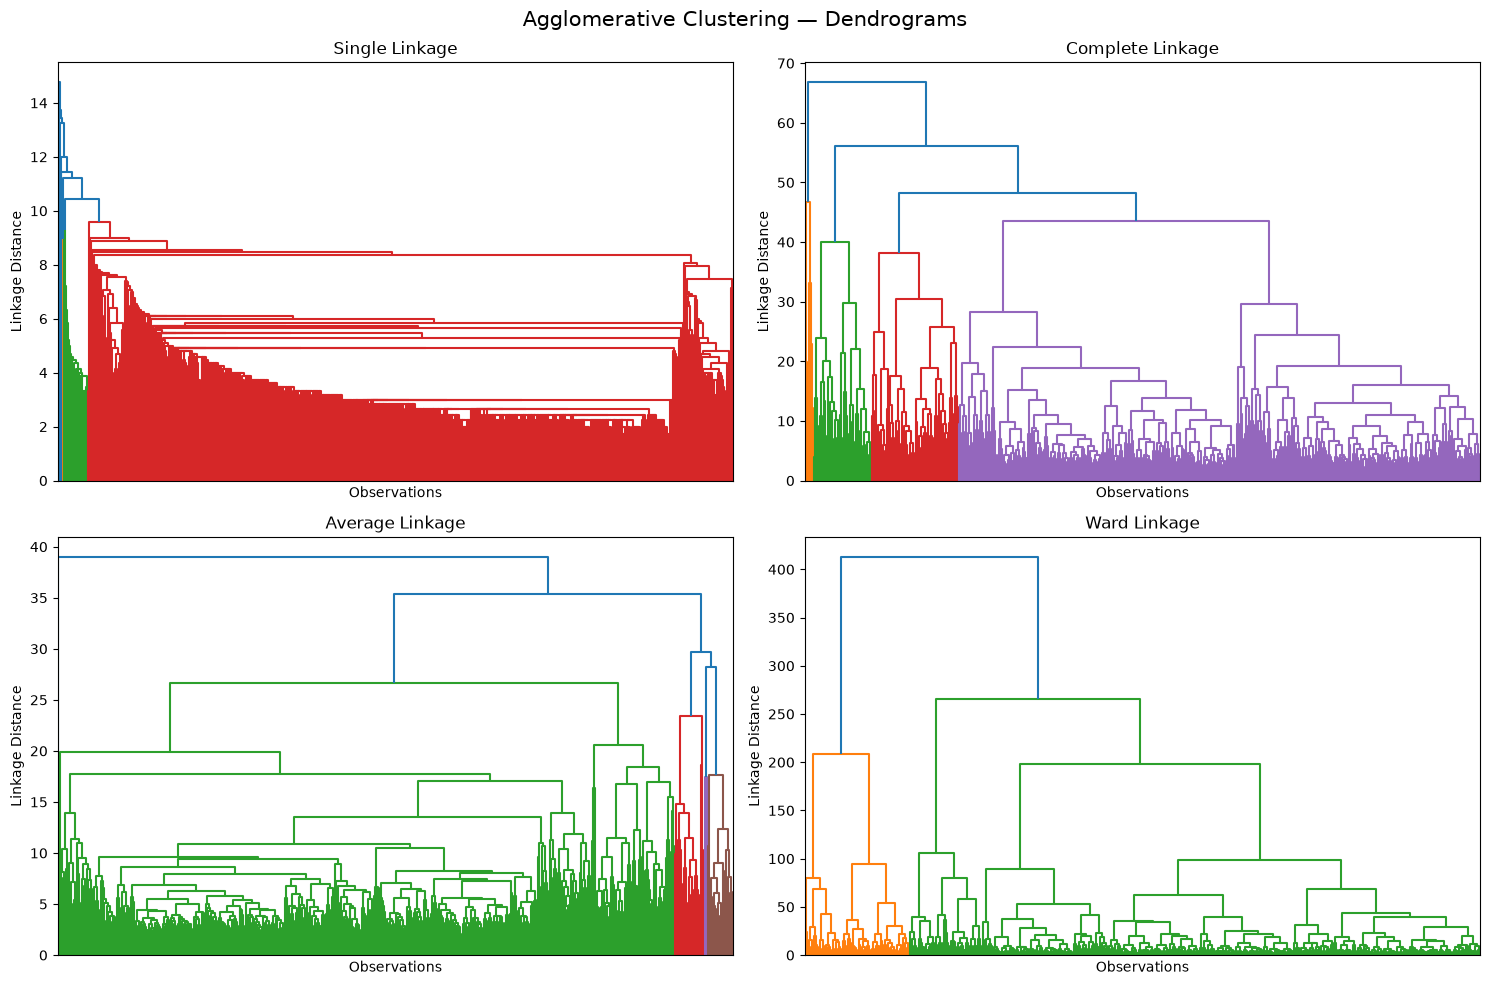

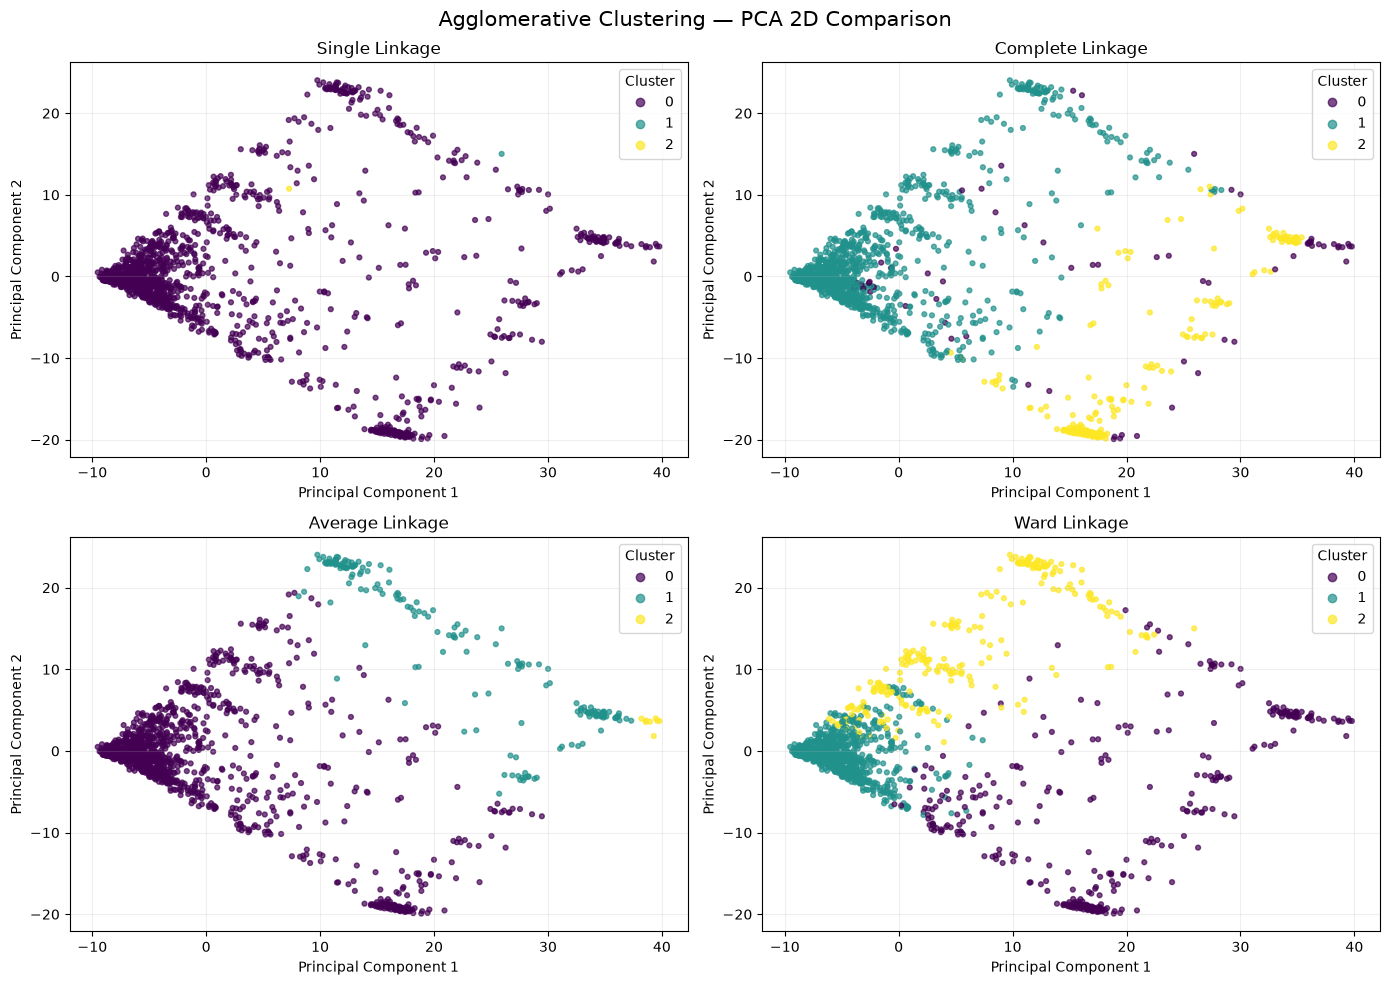

PCA variance explained: 73.15 %


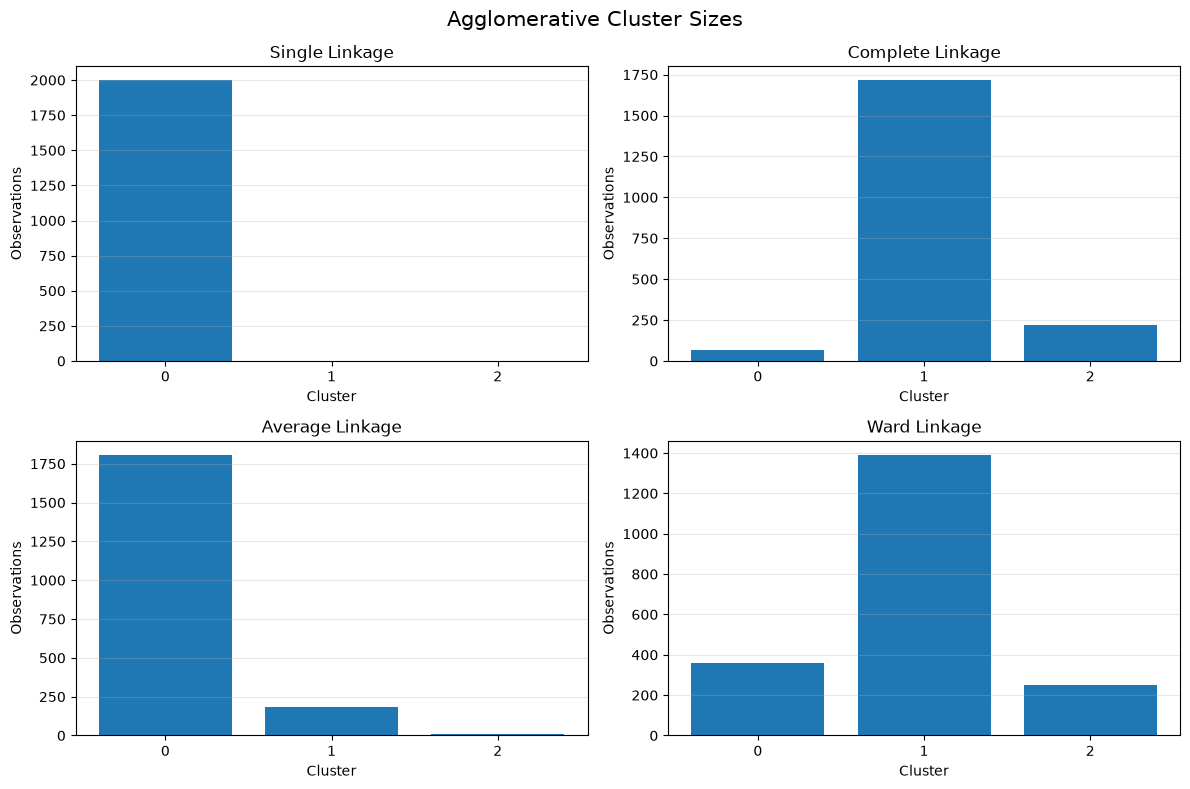

In [21]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import linkage, dendrogram

# ==========================================
# 1. PREPARE THE SAME COMPARISON SAMPLE
# ==========================================
X_array = X.to_numpy() if hasattr(X, "to_numpy") else np.asarray(X)
X_array = np.asarray(X_array, dtype=np.float64)

if not np.isfinite(X_array).all():
    raise ValueError("Clean missing and infinite values in X first.")

rng = np.random.default_rng(42)
sample_size = min(2000, len(X_array))
sample_idx = np.sort(
    rng.choice(len(X_array), sample_size, replace=False)
)
X_compare = X_array[sample_idx]

chosen_k = 3
linkage_methods = ["single", "complete", "average", "ward"]

# ==========================================
# 2. FIT AGGLOMERATIVE MODELS
# ==========================================
agg_labels = {}
results = []

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=chosen_k,
        linkage=method,
        metric="euclidean"
    )

    labels = model.fit_predict(X_compare)
    agg_labels[method] = labels

    n_clusters = len(np.unique(labels))

    print(f"\nLinkage: {method}")
    print("Cluster labels:", np.unique(labels))
    print("Cluster sizes:", np.bincount(labels))

    if 1 < n_clusters < len(X_compare):
        results.append({
            "Algorithm": f"Agglomerative - {method}",
            "Clusters": n_clusters,
            "Silhouette Score": silhouette_score(
                X_compare, labels
            ),
            "Davies-Bouldin Index": davies_bouldin_score(
                X_compare, labels
            ),
            "Calinski-Harabasz Index": calinski_harabasz_score(
                X_compare, labels
            )
        })
    else:
        print("Metrics skipped: invalid number of clusters.")

# ==========================================
# 3. EVALUATION METRICS TABLE
# ==========================================
agg_metrics = pd.DataFrame(results)

print("\nAGGLOMERATIVE CLUSTERING METRICS")
print(agg_metrics.round(4).to_string(index=False))

# ==========================================
# 4. DENDROGRAMS
# ==========================================
dendrogram_rows = min(1000, len(X_array))
dendrogram_idx = np.sort(
    rng.choice(len(X_array), dendrogram_rows, replace=False)
)
X_dendro = X_array[dendrogram_idx]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

for ax, method in zip(axes, linkage_methods):
    Z = linkage(
        X_dendro,
        method=method,
        metric="euclidean"
    )

    dendrogram(
        Z,
        ax=ax,
        no_labels=True
    )

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Observations")
    ax.set_ylabel("Linkage Distance")

fig.suptitle(
    "Agglomerative Clustering — Dendrograms",
    fontsize=15
)
plt.tight_layout()
plt.show()

# ==========================================
# 5. PCA 2D VISUALISATION FOR ALL LINKAGES
# ==========================================
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_compare)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, method in zip(axes, linkage_methods):
    labels = agg_labels[method]

    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=12,
        alpha=0.7
    )

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend(*scatter.legend_elements(), title="Cluster")
    ax.grid(True, alpha=0.2)

fig.suptitle(
    "Agglomerative Clustering — PCA 2D Comparison",
    fontsize=15
)
plt.tight_layout()
plt.show()

print(
    "PCA variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# ==========================================
# 6. CLUSTER SIZE COMPARISON
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, method in zip(axes, linkage_methods):
    cluster_ids, counts = np.unique(
        agg_labels[method], return_counts=True
    )

    ax.bar(cluster_ids, counts)
    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Observations")
    ax.set_xticks(cluster_ids)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Agglomerative Cluster Sizes", fontsize=15)
plt.tight_layout()
plt.show()
